In [207]:
import numpy as np
import pandas as pd
import random
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize)

In [208]:
from ISLP import confusion_table
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

This project looks to answer the question "What predicts state-level net migration?"
Many Americans make the choice of moving state-to-state, and this research looks to examine into that more.

From the following research, the expected result is that higher unemployment predicts lower net domestic migration, and larger or denser states have different migration rates.

The datasets that will be utilized are as listed below:
1. United States Census Bureau population estimates from 2010-2019
2. Unemployment in the United States from 1976-2022 from Kaggle

In [209]:
# SECTION 2: First setting the random seed
random.seed(100)

In [210]:
# SECTION 2: All need filepaths
Population_data = pd.read_csv('nst-est2019-alldata.csv')
Unemployment_data = pd.read_csv('Unemployment in America Per US State.csv')

In [211]:
# SECTION 3: Loading and cleaning the data
# Check the shape, dtypes, and missing values for population data
print("Current shape of the whole population data:", Population_data.shape, Population_data.dtypes)

# Filter to the 50 states + DC: drop the U.S. total, the 4 regions, the division rows (SUMLEV 010/020/030) and Puerto Rico
clean_population = Population_data.copy()

clean_population = clean_population[clean_population['SUMLEV'] == 40]
# print(clean_population['NAME'])

# Remove Puerto Rico, becuase it doesn't have any values
clean_population = clean_population[clean_population['NAME'] != 'Puerto Rico']
# print(clean_population['NAME'])

# Reset the index
clean_population = clean_population.reset_index(drop=True)
# print(clean_population['NAME'])

# Remove the manual patches (loc[56, 'REGION')=0, DIVISION 'X' replace) once the rows are filtered out
print("No need to remove manual patches because the data points containing 'X''s have been removed")

# Turn the 'REGION' and 'DIVISION' columns into numeric
clean_population['REGION'] = pd.to_numeric(clean_population['REGION'])
clean_population['DIVISION'] = pd.to_numeric(clean_population['DIVISION'])

print("'REGION' data-type: ",clean_population['REGION'].dtypes)
print("'DIVISION' data-type: ",clean_population['DIVISION'].dtypes)

# Don't use pd.to_numeric(errors='coerce') on the whole DataFrame. Convert only the numeric columns, and check for new NaNs

# Reshape to long format: one row per (state, year) with columns such as population, births, deaths, net migration, domestic migration
print(clean_population.columns)

# First: fix NPOPCHG_2010-2019 because it has an underscore that will mess with the rest of the renaming
clean_population = clean_population.rename(columns={f'NPOPCHG_{y}' : f'NPOPCHG{y}' for y in range(2010, 2020)})


No need to remove manual patches because the data points containing 'X''s have been removed
'REGION' data-type:  int64
'DIVISION' data-type:  int64
Index(['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'CENSUS2010POP',
       'ESTIMATESBASE2010', 'POPESTIMATE2010', 'POPESTIMATE2011',
       'POPESTIMATE2012',
       ...
       'RDOMESTICMIG2019', 'RNETMIG2011', 'RNETMIG2012', 'RNETMIG2013',
       'RNETMIG2014', 'RNETMIG2015', 'RNETMIG2016', 'RNETMIG2017',
       'RNETMIG2018', 'RNETMIG2019'],
      dtype='object', length=151)


In [233]:
import re
cols = [c for c in clean_population.columns if re.search(r'\d{4}$', c)]
stubs = {}

for c in cols:
    stub = re.sub(r'_?\d{4}$', '', c)
    stubs.setdefault(stub, []).append(int(c[-4:]))

stubs_list = []
for s, yrs in stubs.items():
    stubs_list.append(s)
    print(s, min(yrs), max(yrs), len(yrs))

identifiers_list = ['NAME', 'STATE', 'REGION', 'DIVISION', 'CENSUS2010POP']
stubs_list.remove('ESTIMATESBASE')
stubs_list.remove('RESIDUAL')
print("Stubs list: ", stubs_list)

ESTIMATESBASE 2010 2010 1
POPESTIMATE 2010 2019 10
NPOPCHG 2010 2019 10
BIRTHS 2010 2019 10
DEATHS 2010 2019 10
NATURALINC 2010 2019 10
INTERNATIONALMIG 2010 2019 10
DOMESTICMIG 2010 2019 10
NETMIG 2010 2019 10
RESIDUAL 2010 2019 10
RBIRTH 2011 2019 9
RDEATH 2011 2019 9
RNATURALINC 2011 2019 9
RINTERNATIONALMIG 2011 2019 9
RDOMESTICMIG 2011 2019 9
RNETMIG 2011 2019 9
Stubs list:  ['POPESTIMATE', 'NPOPCHG', 'BIRTHS', 'DEATHS', 'NATURALINC', 'INTERNATIONALMIG', 'DOMESTICMIG', 'NETMIG', 'RBIRTH', 'RDEATH', 'RNATURALINC', 'RINTERNATIONALMIG', 'RDOMESTICMIG', 'RNETMIG']


In [234]:
# Trimming the table and reshaping it
year_cols = []
for stub in stubs_list:
    pattern = re.compile(rf'{stub}\d{{4}}')
    matches = [c for c in clean_population.columns if pattern.fullmatch(c)]
    year_cols.extend(matches)

keep = identifiers_list + year_cols
assert len(keep) == len(set(keep)), "Duplicate columns in keep list"
trimmed = clean_population[keep].copy()

print("Shape:", trimmed.shape) # expect (51, 139)

dropped = sorted(set(clean_population.columns) - set(keep)) 
print("Dropped:", len(dropped), dropped) # expect 12

for stub in stubs_list:
    n = sum(bool(re.fullmatch(rf'{stub}\d{{4}}', c)) for c in trimmed.columns)
    print(stub, n) # expect 10 or 9

# Check that all values match expected before reshaping -- DEBUG PRINTS HERE --
# print("Rows:", len(trimmed))
# print("State unique:", trimmed['STATE'].is_unique)
# print("Total NaNs:", trimmed.isna().sum().sum())
# print(trimmed.drop(columns='NAME').dtypes.value_counts())

# Reshape from wide (one row per state) to long (one row per state-year)
long_df = pd.wide_to_long(
    trimmed,
    stubnames=stubs_list,
    i='STATE',
    j='Year',
    sep=''
).reset_index()

long_df = long_df.sort_values(['STATE', 'Year']).reset_index(drop=True)

# Verify that the reshaping worked
print("Shape:", long_df.shape)
print("Years:", sorted(long_df['Year'].unique()))
print("Duplicate state-years:", long_df.duplicated(['STATE', 'Year']).sum())
print("NaNs per column:", long_df.isna().sum()[long_df.isna().sum() > 0])
print(long_df.head())

Shape: (51, 139)
Dropped: 12 ['ESTIMATESBASE2010', 'RESIDUAL2010', 'RESIDUAL2011', 'RESIDUAL2012', 'RESIDUAL2013', 'RESIDUAL2014', 'RESIDUAL2015', 'RESIDUAL2016', 'RESIDUAL2017', 'RESIDUAL2018', 'RESIDUAL2019', 'SUMLEV']
POPESTIMATE 10
NPOPCHG 10
BIRTHS 10
DEATHS 10
NATURALINC 10
INTERNATIONALMIG 10
DOMESTICMIG 10
NETMIG 10
RBIRTH 9
RDEATH 9
RNATURALINC 9
RINTERNATIONALMIG 9
RDOMESTICMIG 9
RNETMIG 9
Shape: (510, 20)
Years: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]
Duplicate state-years: 0
NaNs per column: RBIRTH               51
RDEATH               51
RNATURALINC          51
RINTERNATIONALMIG    51
RDOMESTICMIG         51
RNETMIG              51
dtype: int64
   STATE  Year  CENSUS2010POP  DIVISION     NAME  REGION  POPESTIMATE  \
0      1  2010        4779736         6  Alabama       3      4785437   
1      1  2011        4779736         6  Alabama       3      4799069   
2      1  2012        4779736         6  Alabama       3      4815588   
3      1  2013       

In [214]:
# Using the Kaggle data, filter for 2010-2019 and merge with the now-cleaned population data
# print(Unemployment_data.head)
# print(Unemployment_data['State/Area'].unique)

clean_unemp = Unemployment_data.copy()
clean_unemp = clean_unemp[~clean_unemp['State/Area'].isin(['Los Angeles County', 'New York city'])]

clean_unemp = clean_unemp[clean_unemp['Year'].between(2010, 2019)]

# Turn the monthly into annual averages
clean_unemp = (
    clean_unemp.groupby(['FIPS Code', 'Year'], as_index=False)
    ['Percent (%) of Labor Force Unemployed in State/Area']
    .mean()
    .rename(columns={
        'FIPS Code': 'STATE',
        'Year': 'Year',
        "Percent (%) of Labor Force Unemployed in State/Area": 'unemp_rate'})
)

print(clean_unemp.shape)
print(clean_unemp['STATE'].nunique())
print(clean_unemp.groupby('STATE').size().unique())
print(clean_unemp['unemp_rate'].describe())

(510, 3)
51
[10]
count    510.000000
mean       5.788824
std        2.247173
min        2.100000
25%        4.010417
50%        5.345833
75%        7.256250
max       13.733333
Name: unemp_rate, dtype: float64


In [235]:
# Merge the unemployment data onto the population data
merged = long_df.merge(clean_unemp, on=['STATE', 'Year'],
                       how='left', validate='one_to_one', indicator=True)

print(merged.columns)
# Fix column order for readaibility
order = ['NAME', 'STATE', 'REGION', 'DIVISION', 'Year', 'CENSUS2010POP',
         'unemp_rate', '_merge',
         'POPESTIMATE', 'NPOPCHG', 'BIRTHS', 'DEATHS', 'NATURALINC',
         'INTERNATIONALMIG', 'DOMESTICMIG', 'NETMIG',
         'RBIRTH', 'RDEATH', 'RNATURALINC', 'RINTERNATIONALMIG',
         'RDOMESTICMIG', 'RNETMIG']

assert set(order) == set(merged.columns), "Missing or extra columns"
merged = merged[order]

print(merged['_merge'].value_counts())
print(merged['unemp_rate'].isna().sum())
merged = merged.drop(columns='_merge')
print(merged.shape)
print(merged.head())

# Only issue is that the year should probably be 2011-2019 because not all the columns from the population data have data for 2010

Index(['STATE', 'Year', 'CENSUS2010POP', 'DIVISION', 'NAME', 'REGION',
       'POPESTIMATE', 'NPOPCHG', 'BIRTHS', 'DEATHS', 'NATURALINC',
       'INTERNATIONALMIG', 'DOMESTICMIG', 'NETMIG', 'RBIRTH', 'RDEATH',
       'RNATURALINC', 'RINTERNATIONALMIG', 'RDOMESTICMIG', 'RNETMIG',
       'unemp_rate', '_merge'],
      dtype='object')
_merge
both          510
left_only       0
right_only      0
Name: count, dtype: int64
0
(510, 21)
      NAME  STATE  REGION  DIVISION  Year  CENSUS2010POP  unemp_rate  \
0  Alabama      1       3         6  2010        4779736   10.375000   
1  Alabama      1       3         6  2011        4779736    9.583333   
2  Alabama      1       3         6  2012        4779736    8.158333   
3  Alabama      1       3         6  2013        4779736    7.325000   
4  Alabama      1       3         6  2014        4779736    6.733333   

   POPESTIMATE  NPOPCHG  BIRTHS  ...  NATURALINC  INTERNATIONALMIG  \
0      4785437     5312   14226  ...        3151               9

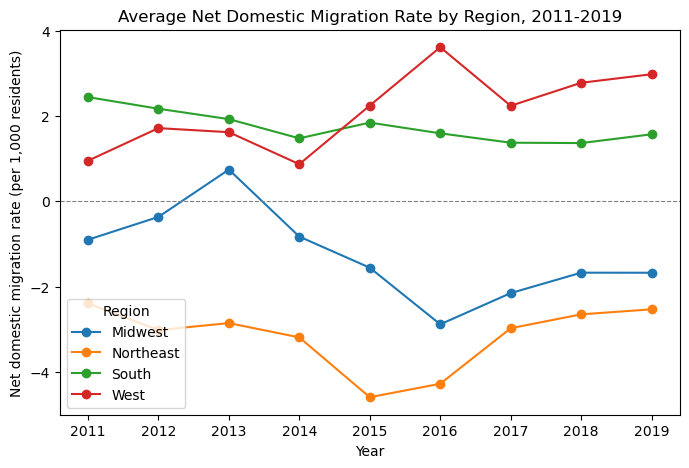

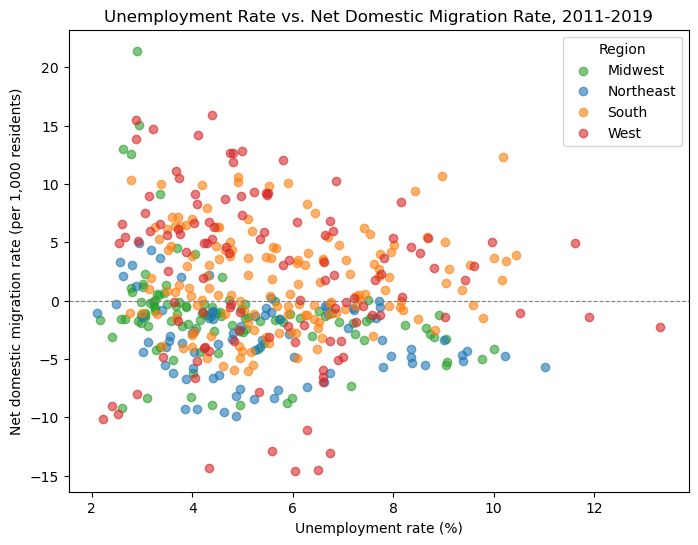

In [237]:
# SECTION 4: Exploratory data analysis

summary_statistics = merged.describe()
# print(summary_statistics)

# Plot net migration by region over time (line chart, one line per region)
import matplotlib.pyplot as plt

region_names = {1: 'Northeast', 2: 'Midwest', 3: 'South', 4:'West'}
merged['region_name'] = merged['REGION'].map(region_names)

region_trend = (merged[merged['Year'] >= 2011]
                .groupby(['Year', 'region_name'])['RDOMESTICMIG']
                .mean()
                .unstack('region_name'))

ax_1 = region_trend.plot(marker='o', figsize=(8,5))
ax_1.set_title('Average Net Domestic Migration Rate by Region, 2011-2019')
ax_1.set_xlabel('Year')
ax_1.set_ylabel('Net domestic migration rate (per 1,000 residents)')
ax_1.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax_1.legend(title='Region')
plt.show()

# Plot unemployment vs. net migration (scatterplot, colored by region)
unemployment_migration_trend = (merged[merged['Year'] >= 2011]
                                .groupby(['unemp_rate', 'region_name'])['RDOMESTICMIG']
                                .mean()
                                .unstack('region_name'))

region_colors = {'Northeast': 'tab:blue', 'Midwest': 'tab:green',
                 'South': 'tab:orange', 'West': 'tab:red'}

fig, ax_2 = plt.subplots(figsize=(8, 6))
for region, grp in merged.groupby('region_name'):
    ax_2.scatter(grp['unemp_rate'], grp['RDOMESTICMIG'],
               label=region, color=region_colors[region], alpha=0.6)

ax_2.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax_2.set_title('Unemployment Rate vs. Net Domestic Migration Rate, 2011-2019')
ax_2.set_xlabel('Unemployment rate (%)')
ax_2.set_ylabel('Net domestic migration rate (per 1,000 residents)')
ax_2.legend(title='Region')
plt.show()
                                         

region_name   Midwest  Northeast     South      West
region_name                                         
Midwest      1.000000   0.400706  0.521902 -0.707164
Northeast    0.400706   1.000000  0.137399 -0.358192
South        0.521902   0.137399  1.000000 -0.508782
West        -0.707164  -0.358192 -0.508782  1.000000


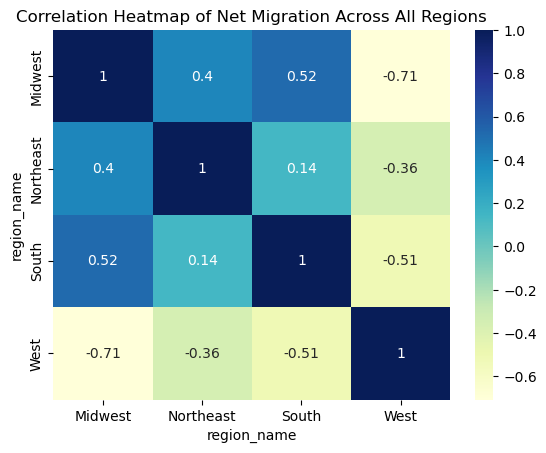

                   unemp_rate  RDOMESTICMIG  RINTERNATIONALMIG  RNETMIG  \
unemp_rate               1.00         -0.08               0.10    -0.05   
RDOMESTICMIG            -0.08          1.00              -0.11     0.96   
RINTERNATIONALMIG        0.10         -0.11               1.00     0.17   
RNETMIG                 -0.05          0.96               0.17     1.00   
RBIRTH                   0.09          0.09              -0.01     0.09   
RDEATH                  -0.11         -0.03              -0.36    -0.13   
RNATURALINC              0.11          0.07               0.18     0.13   

                   RBIRTH  RDEATH  RNATURALINC  
unemp_rate           0.09   -0.11         0.11  
RDOMESTICMIG         0.09   -0.03         0.07  
RINTERNATIONALMIG   -0.01   -0.36         0.18  
RNETMIG              0.09   -0.13         0.13  
RBIRTH               1.00   -0.49         0.88  
RDEATH              -0.49    1.00        -0.84  
RNATURALINC          0.88   -0.84         1.00  


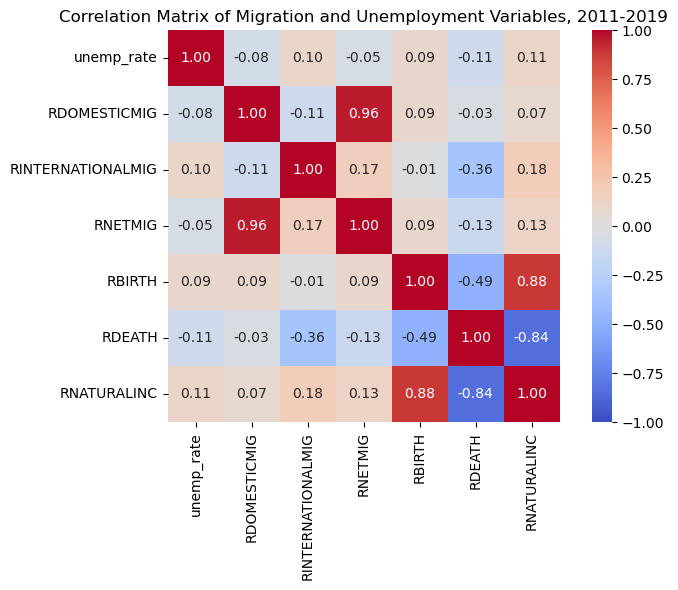

In [238]:
# Creating a correlation heatmap of the features I'm going to be using
import seaborn as sns

# Steps
# 1. Make the correlation matrix (in this case, we will use the above Region and Net Migration Trends)
co_matrix = region_trend.corr(numeric_only=True)

# 2. Verify by printing
print(co_matrix)

# 3. Plot the correlation heatmap 
heat_map = sns.heatmap(co_matrix, cmap="YlGnBu", annot=True)
plt.title('Correlation Heatmap of Net Migration Across All Regions')
# 4. Display correlation map
plt.show()

# Part 2: Correlation heatmap adjacent to the scatterplot
## Note to self: Need to fix axis labels for variables so they make sense ##
heat_cols = ['unemp_rate', 'RDOMESTICMIG', 'RINTERNATIONALMIG', 'RNETMIG',
             'RBIRTH', 'RDEATH', 'RNATURALINC']

corr = merged.loc[merged['Year'] >= 2011, heat_cols].corr()
print(corr.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title('Correlation Matrix of Migration and Unemployment Variables, 2011-2019')
plt.tight_layout()
plt.show()

In [239]:
# Replace the previous index-based line plots with sorted bar charts or a chart indexed by state name
# Add titles, axis labels, units

# Maybe start with Net Domestic Migration Rate by State with a Bar Chart?
# Maybe make each plot by region because it may be unrealistic to put them all on one chart

# Start with Midwest
midwest_trend = (merged[merged['region_name'] == 'Midwest']
                   .groupby(['NAME', 'region_name'])['RDOMESTICMIG']
                   .mean()
                   .unstack('region_name'))

# ax_3 = midwest_trend.plot.bar(figsize=(8,5), color='orange')
# ax_3.axhline(0, color='gray', linewidth=0.8, linestyle='--')
# ax_3.set_title('Net Domestic Migration Rate Across Midwest States')
# ax_3.set_xlabel('States')
# ax_3.set_ylabel('Net Domestic Migration Rate (per 1,000 residents)')
# ax_3.legend(title='Region')
# plt.show()

# Northeast (color: blue)
northeast_trend = (merged[merged['region_name'] == 'Northeast']
                   .groupby(['NAME', 'region_name'])['RDOMESTICMIG']
                   .mean()
                   .unstack('region_name'))

# ax_3 = northeast_trend.plot.bar(figsize=(8,5), color='blue')
# ax_3.axhline(0, color='gray', linewidth=0.8, linestyle='--')
# ax_3.set_title('Net Domestic Migration Rate Across Northeast States')
# ax_3.set_xlabel('States')
# ax_3.set_ylabel('Net Domestic Migration Rate (per 1,000 residents)')
# ax_3.legend(title='Region')
# plt.show()

# South (color: green)
south_trend = (merged[merged['region_name'] == 'South']
                   .groupby(['NAME', 'region_name'])['RDOMESTICMIG']
                   .mean()
                   .unstack('region_name'))

# ax_3 = south_trend.plot.bar(figsize=(8,5), color='green')
# ax_3.axhline(0, color='gray', linewidth=0.8, linestyle='--')
# ax_3.set_title('Net Domestic Migration Rate Across Southern States')
# ax_3.set_xlabel('States')
# ax_3.set_ylabel('Net Domestic Migration Rate (per 1,000 residents)')
# ax_3.legend(title='Region')
# plt.show()

# West (color: red)
west_trend = (merged[merged['region_name'] == 'West']
                   .groupby(['NAME', 'region_name'])['RDOMESTICMIG']
                   .mean()
                   .unstack('region_name'))

# ax_3 = west_trend.plot.bar(figsize=(8,5), color='red')
# ax_3.axhline(0, color='gray', linewidth=0.8, linestyle='--')
# ax_3.set_title('Net Domestic Migration Rate Across Western States')
# ax_3.set_xlabel('States')
# ax_3.set_ylabel('Net Domestic Migration Rate (per 1,000 residents)')
# ax_3.legend(title='Region')
# plt.show()

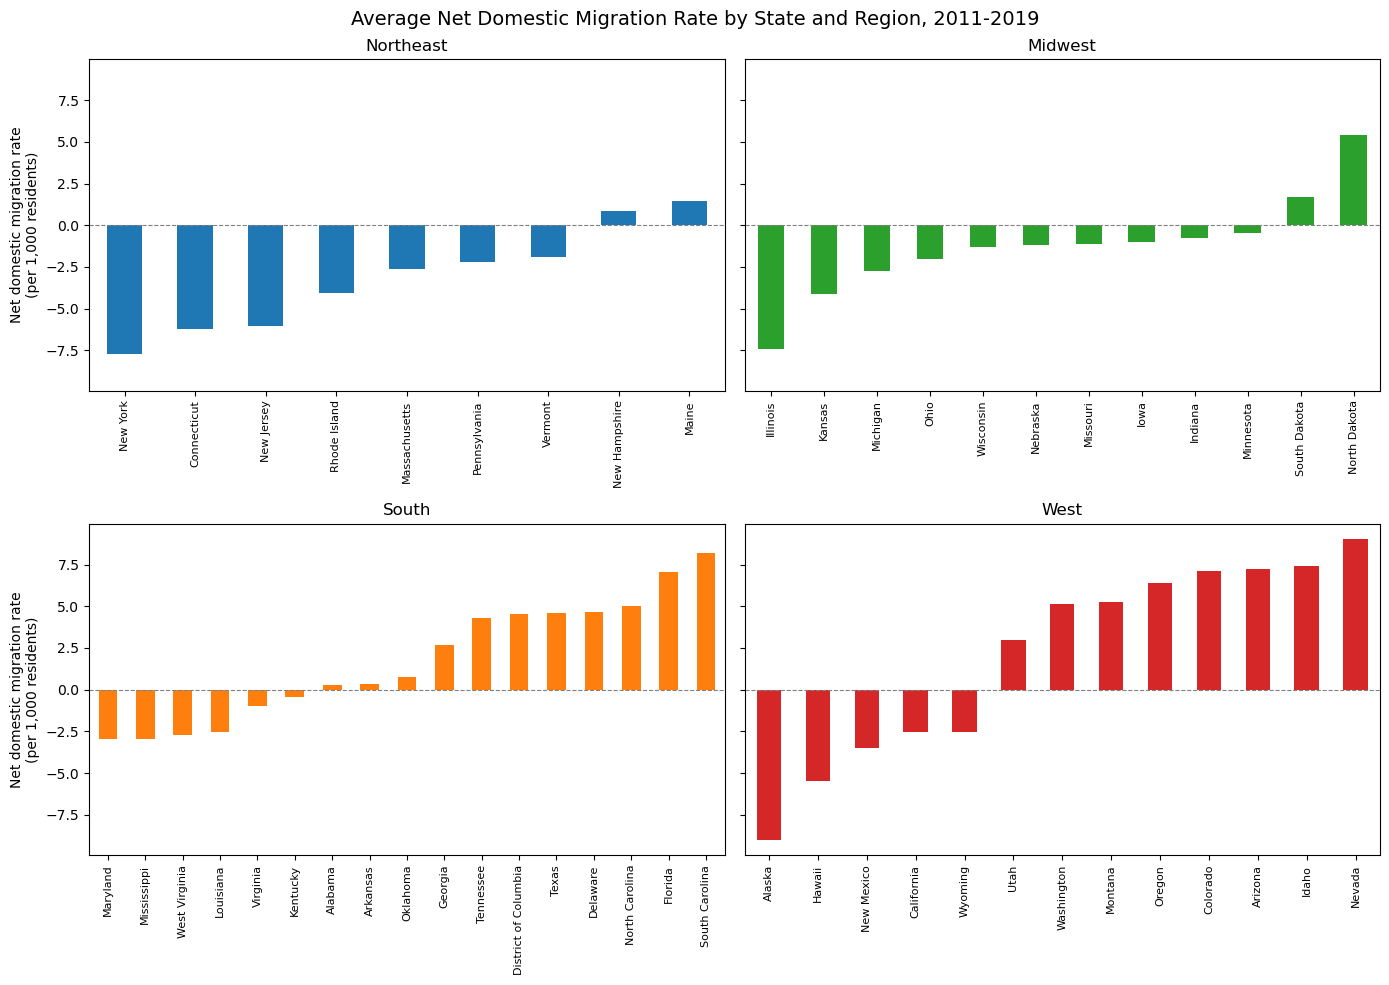

In [219]:
# Grid of all the net domestic migration rates for states by region
plot_df = merged[merged['Year'] >= 2011]

regions = ['Northeast', 'Midwest', 'South', 'West']

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)

for ax_4, region in zip(axes.flat, regions):
    region_trend_2 = (plot_df[plot_df['region_name'] == region]
                      .groupby('NAME')['RDOMESTICMIG']
                      .mean()
                      .sort_values())

    region_trend_2.plot.bar(ax=ax_4, color=region_colors[region])
    ax_4.axhline(0, color='gray', linewidth=0.8, linestyle='--')
    ax_4.set_title(region)
    ax_4.set_xlabel('')
    ax_4.tick_params(axis='x', labelsize=8)

for ax in axes[:, 0]:
    ax.set_ylabel('Net domestic migration rate\n(per 1,000 residents)')

fig.suptitle('Average Net Domestic Migration Rate by State and Region, 2011-2019', fontsize=14)
plt.tight_layout()
plt.show() 


In [220]:
# Building the lags, growth rate, shifted target, and dummy variables

# Step 1: Sort and check the years
panel = merged.sort_values(['STATE', 'Year']).reset_index(drop=True)

ok = panel.groupby('STATE')['Year'].apply(lambda y: (y.diff().dropna() == 1).all())
print(ok.all())

True


In [221]:
# Step 2: Build the lag and growth columns
g = panel.groupby('STATE')

panel['unemp_lag1'] = g['unemp_rate'].shift(1)

prev_pop = g['POPESTIMATE'].shift(1)
panel['pop_growth'] = (panel['POPESTIMATE'] - prev_pop) / prev_pop * 100

In [222]:
# Step 3: Build the shifted target
panel['next_rate'] = g['RDOMESTICMIG'].shift(-1)

# Step 4 & 5: Drop unusable rows, then create the binary target
panel = panel.dropna(subset=['RDOMESTICMIG', 'next_rate']).copy()

panel['target'] = (panel['next_rate'] > 0).astype(int)

dummies = (pd.get_dummies(panel['region_name'], prefix='region', dtype=int)
           .drop(columns='region_Northeast'))
# Note: We drop one region to prevent perfect collinearity in the regression; If all four are kept
# then they will allows sum to 1
panel = pd.concat([panel, dummies], axis=1)

In [223]:
# Step 6: Assemble X and Y
features = ['unemp_rate', 'unemp_lag1', 'RDOMESTICMIG', 'pop_growth'] + list(dummies.columns)
X = panel[features]
y = panel['target']

In [224]:
# Step 7: Check the cells
print("Rows:", len(panel))
print("Years:", sorted(panel['Year'].unique()))
print("Features:", features)
print("NaNs in X:", X_original.isna().sum().sum())
print("Class balance:\n", y_original.value_counts(normalize=True))

Rows: 408
Years: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]
Features: ['unemp_rate', 'unemp_lag1', 'RDOMESTICMIG', 'pop_growth', 'region_Midwest', 'region_South', 'region_West']
NaNs in X: 0
Class balance:
 target
0    0.583333
1    0.416667
Name: proportion, dtype: float64


In [225]:
# Training & Testing Sets
import numpy

numpy.random.seed(100)

training_data = panel.copy()
training_data = training_data['Year'] < 2017

testing_data = panel.copy()
testing_data = testing_data['Year'] >= 2017

x_train, y_train = panel.loc[training_data, features], panel.loc[training_data, 'target']
x_test, y_test = panel.loc[testing_data, features], panel.loc[testing_data, 'target']

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.fit_transform(x_test)

# Verify outputs
print("Train:", X_train_scaled.shape, y_train.shape)
print("Test:", X_test_scaled.shape, y_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))
print("Test class balance:\n", y_test.value_counts(normalize=True))

Train: (306, 7) (306,)
Test: (102, 7) (102,)
Train class balance:
 target
0    0.594771
1    0.405229
Name: proportion, dtype: float64
Test class balance:
 target
0    0.54902
1    0.45098
Name: proportion, dtype: float64


In [226]:
# Baselines (for inflow/outflow)
majority = y_train.mode()[0]
print("Majority-class baseline:", (y_test == majority).mean())

persist = (x_test['RDOMESTICMIG'] > 0).astype(int)
print("Persistence baseline:", (persist == y_test).mean())

Majority-class baseline: 0.5490196078431373
Persistence baseline: 0.9607843137254902


In [227]:
# Check the VIF for collinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = sm.add_constant(x_train.astype(float))
vif_data = pd.DataFrame({'feature': X_vif.columns,
                         'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
print(vif_data.round(2))

# Logistic Regression
clf = LogisticRegression(max_iter=10000, random_state=0)
clf.fit(X_train_scaled, y_train)

logit = sm.Logit(y_train, sm.add_constant(x_train.astype(float))).fit(
    cov_type='cluster',
    cov_kwds={'groups': panel.loc[training_data, 'STATE']},
    disp=0)

print(logit.summary())
print(logit.wald_test('unemp_rate = 0, unemp_lag1 = 0', scalar=True))

acc = accuracy_score(y_test, clf.predict(X_test_scaled)) * 100
print(f"Logistic Regression model accuracy: {acc:.2f}%")

          feature    VIF
0           const  21.35
1      unemp_rate  19.96
2      unemp_lag1  19.72
3    RDOMESTICMIG   4.15
4      pop_growth   4.44
5  region_Midwest   1.88
6    region_South   2.34
7     region_West   2.36
                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                  306
Model:                          Logit   Df Residuals:                      298
Method:                           MLE   Df Model:                            7
Date:                Tue, 13 Oct 2026   Pseudo R-squ.:                  0.6121
Time:                        17:47:14   Log-Likelihood:                -80.129
converged:                       True   LL-Null:                       -206.57
Covariance Type:              cluster   LLR p-value:                 6.729e-51
                     coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------

In [228]:
# KNN (K-Nearest Neighbors)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

acc_knn = accuracy_score(y_test, knn.predict(X_test_scaled)) * 100
print(f"K-Nearest Neighbors test accuracy (k=5): {acc_knn:.2f}%")

# KNN with Grid-Search CV
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

years = panel.loc[training_data, 'Year'].values
cv_splits = [(np.where(years < v)[0], np.where(years == v)[0]) for v in range(2013, 2017)]

param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

pipe = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier())])
grid_search = GridSearchCV(
    pipe,
    param_grid=param_grid,
    cv=cv_splits,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Validation Accuracy: {grid_search.best_score_:.4f}")

best_knn = grid_search.best_estimator_
acc_knn_2 = best_knn.score(x_test, y_test)
print(f"Final Test Accuracy: {acc_knn_2:.4f}")


K-Nearest Neighbors test accuracy (k=5): 87.25%
Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}
Best Validation Accuracy: 0.8971
Final Test Accuracy: 0.9020


In [229]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train_scaled, y_train)

rf_y_pred = rf_classifier.predict(X_test_scaled)

acc_rf = accuracy_score(y_test, rf_y_pred)
classification_rep = classification_report(y_test, rf_y_pred)
print(f"Random Forest test accuracy: {acc_rf:.2f}")
print("\nClassification Report:\n", classification_rep)

imp = pd.Series(rf_classifier.feature_importances_, index=features).sort_values(ascending=False)
print(imp.round(3))

Random Forest test accuracy: 0.92

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.96      0.93        56
           1       0.95      0.87      0.91        46

    accuracy                           0.92       102
   macro avg       0.93      0.92      0.92       102
weighted avg       0.92      0.92      0.92       102

RDOMESTICMIG      0.503
pop_growth        0.254
unemp_lag1        0.089
unemp_rate        0.080
region_South      0.028
region_West       0.027
region_Midwest    0.019
dtype: float64


In [230]:
# Build comparison table: model, test metric(s), and the baseline

# Make the regression (similarly to the logit one, with RSME  and R-square)

# Classification: accuracy, precision, recall, and a confusion matrix
# whole rows and columns are true vs. predicted labels (not population counts)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

preds = {
    'Majority class': np.full(len(y_test), y_train.mode()[0]),
    'Persistence rule': (x_test['RDOMESTICMIG'] > 0).astype(int),
    'Logistic regression': clf.predict(X_test_scaled),
    'KNN (tuned)': best_knn.predict(x_test),
    'Random forest': rf_classifier.predict(X_test_scaled)
}

rows = []
for name, p in preds.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p, zero_division=0),
        'Recall': recall_score(y_test, p, zero_division=0),
        'F1': f1_score(y_test, p, zero_division=0),
    })

results = pd.DataFrame(rows).set_index('Model')
results['vs. persistence'] = results['Accuracy'] - results.loc['Persistence rule', 'Accuracy']
print(results.round(3))

# Caption: Table 2. Test-set performance (2017-2018, n=102) for predicting next-year net domestic inflow.
# Baselines in the first two rows.

                     Accuracy  Precision  Recall     F1  vs. persistence
Model                                                                   
Majority class          0.549      0.000   0.000  0.000           -0.412
Persistence rule        0.961      0.957   0.957  0.957            0.000
Logistic regression     0.902      0.974   0.804  0.881           -0.059
KNN (tuned)             0.902      0.909   0.870  0.889           -0.059
Random forest           0.922      0.952   0.870  0.909           -0.039


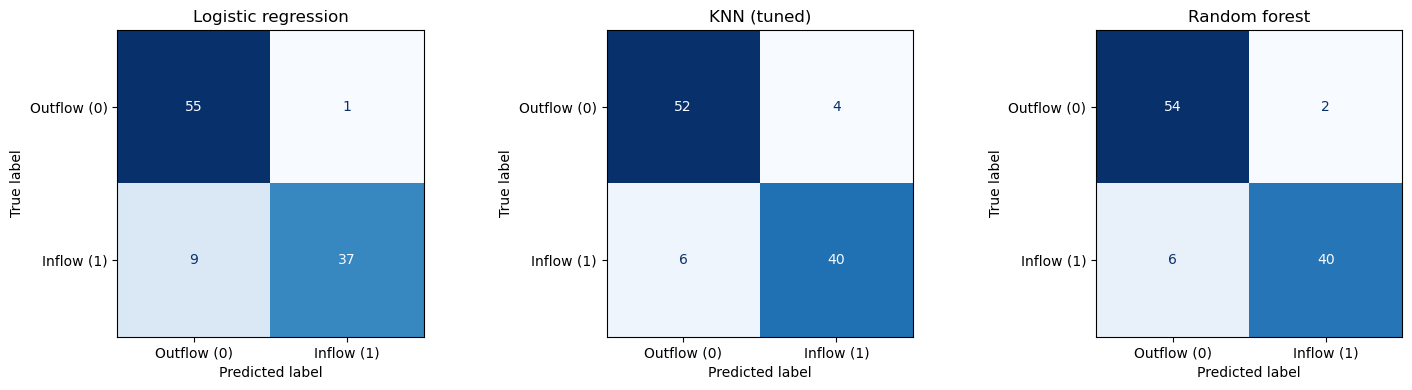

In [231]:
# RSME and R-Squared for regression

# Confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ['Logistic regression', 'KNN (tuned)', 'Random forest']):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[name],
        display_labels=['Outflow (0)', 'Inflow (1)'],
        cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()